In [21]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score


In [5]:
data = {
    'Hours': [1,2,3,4,5,6],
    'Score': [52,57,65,70,75,80]
}

df = pd.DataFrame(data)
df

,Hours,Score
0,1,52
1,2,57
2,3,65
3,4,70
4,5,75
5,6,80


In [15]:
x = df[['Hours']].values # 'values' this returns this columns as arrays
y = df['Score'].values

print(x)

model = LinearRegression()
model.fit(x,y)

predicted_score = model.predict(x)

#lets Evalte the model

mae = mean_absolute_error(y,predicted_score)
mse = mean_squared_error(y,predicted_score)
rmse = np.sqrt(mse)

print(mae,mse,rmse)

Hours = float(input('enter a hour: '))
new_pred = model.predict([[Hours]])
print(new_pred[0])

[[1]
 [2]
 [3]
 [4]
 [5]
 [6]]
0.6666666666666643 0.6285714285714282 0.7928249671720916


enter a hour:  6


80.71428571428571


In [20]:
#this is second project 
data = pd.read_csv('data/Student_performance_data _.csv')

data.head()

data.shape

# data.isnull().sum()

data.describe()

data.info()



<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


In [36]:
#traing the data

from sklearn.model_selection import train_test_split

#list of coolumns that we want to train the data on
features = [
    'StudyTimeWeekly',
    'Absences',
    'ParentalSupport',
    'Tutoring',
    'ParentalEducation',
    'Extracurricular'
]

x = data[features].values
y = data['GPA'].values

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(x_train,y_train)

prec_scores = model.predict(x_test)

#valid regression matrix

mae = mean_absolute_error(y_test,prec_scores)
mse = mean_squared_error(y_test,prec_scores)
rmse = np.sqrt(mse) 
r2 = r2_score(y_test,prec_scores)


print(round(mae,2))
print(round(mse,2))
print(round(rmse,2))
print(round(r2,4))

0.17
0.05
0.22
0.9388


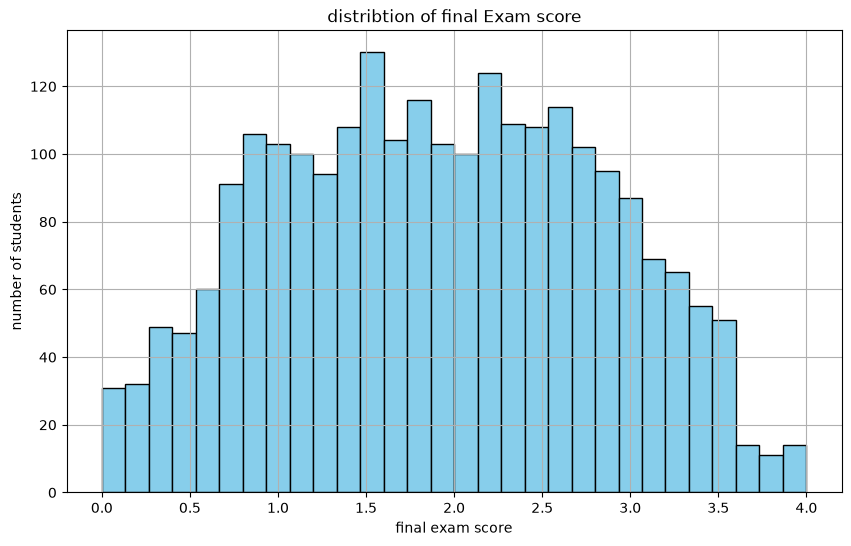

In [37]:
#histograph

plt.figure(figsize=(10,6))

plt.hist(data['GPA'],bins=30,color='skyblue',edgecolor='black')
plt.title('distribtion of final Exam score')
plt.xlabel('final exam score')
plt.ylabel('number of students')
plt.grid(True)
plt.show()

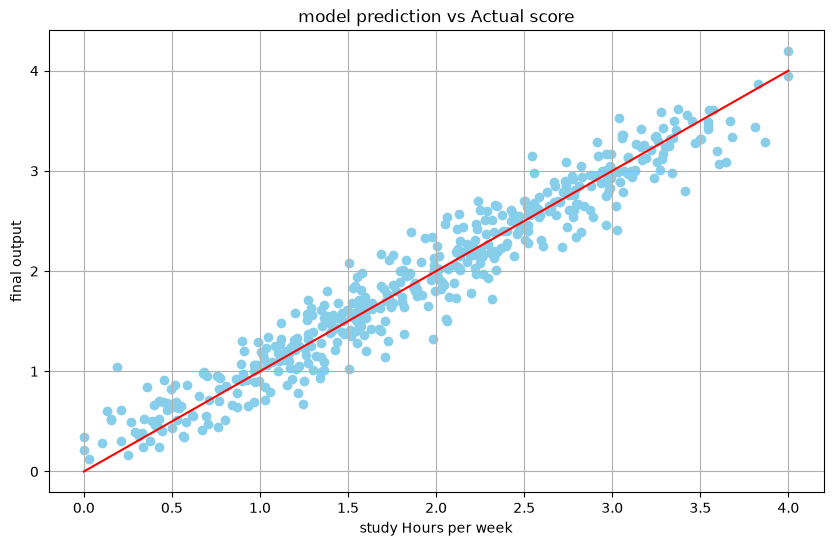

3.310264665819078


In [42]:
#scatter plot 
plt.figure(figsize=(10,6))

plt.scatter(y_test,prec_scores,color='skyblue',label='Actual score')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],color='red',label='Predicated Scocre regression line')
plt.title('model prediction vs Actual score')
plt.xlabel('study Hours per week')
plt.ylabel('final output')
plt.grid(True)
plt.show()

new_hour = [[9.0, 3, 2, 1, 2, 1]]
predicted_new_score = model.predict(new_hour)[0]
print(predicted_new_score)